# PA 2025 Unet implementation on TM 2025-26 synthetic data

Most of this document is a take directly from my PA "Astronomical Adaptive Optics Point Spread Function Reconstruction with Machine Learning Algorithms" (HES-SO master, 1001, Lausanne) with some minor adjustments to make it work with PyTorch.

## Inputs

In [ ]:
outputDir = "output_ML/"
inputDir = "output_prep/"

stabilisation_delay = 100

rng_SEED = 42
train_split = 0.8

GPU = True

SMALL_SIZE = 20
MEDIUM_SIZE = 20
BIGGER_SIZE = 25

In [119]:
%matplotlib widget
import os
os.environ["KERAS_BACKEND"] = "torch"
import torch
import keras
import h5py
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm  # tqdm: merci Jonathan!

In [64]:
def pixel_adder(data, scale_factor = [1,1], final_shape = None):
    """
    Generates a phase screen base on a Phase Spectrum Density (PSD)
    Parameters:
        data (ndarray): source data
        scale_factor (floar): scalling factor. Can be > or < o
        final_shape (ndarray): Option to input directly the desired shape. final_shape/data.shape must be an integer or the final shape will be data.shape*(final_shape//data.shape).
    Returns (list):
        D_phi (ndarray): 2D array representing the phase structure
    TODO: Error check
    """

    datashape = data.shape

    if final_shape == None:
        iscale = scale_factor[0]
        jscale = scale_factor[1]
        image_scaled = np.zeros((int(scale_factor[0]*datashape[0]), int(scale_factor[1]*datashape[1])))
    else:
        iscale = int(final_shape[0]/datashape[0])
        jscale = int(final_shape[1]/datashape[1])
        image_scaled = np.zeros((int(final_shape[0]), int(final_shape[1])))
        
    for i in range(0, datashape[0]):
        for j in range(0, datashape[1]):
            iscaled = i*iscale
            jscaled = j*jscale
            image_scaled[int(iscaled):int(iscaled+iscale), int(jscaled):int(jscaled+jscale)] = data[i,j]
            # print(data[i,j])

    return image_scaled

In [86]:
print(torch.__version__)
print(keras.__version__)
print(torch.cuda.is_available())

2.12.0+cu132
3.14.1
True


(10100, 80, 80)
(10100, 80, 80)
(10100, 2, 80, 80)
(10100, 80, 80)


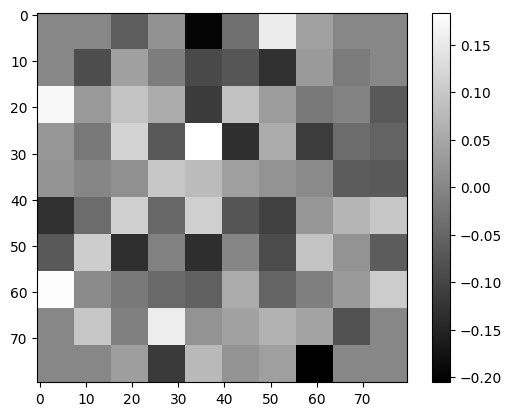

In [69]:
# TODO: make size dynamic
image_size = (80, 80)
WFS_x = np.zeros((10100, *image_size)) # *tuple expands the tuple into separate arguments. Very nice and to be remembered
WFS_y = np.zeros((10100, *image_size))

with h5py.File(inputDir+"ao_WFS_x_prep_1.h5", 'r') as temp:
    key = list(temp.keys())
    # WFS_x = pixel_adder(temp[key[0]][()][:], scale_factor = [8,8], final_shape = None)
    tempData = temp[key[0]][()][:]
    for i in range(tempData.shape[0]):
        WFS_x[i] = pixel_adder(tempData[i], final_shape= [80, 80])

with h5py.File(inputDir+"ao_WFS_y_prep_1.h5", 'r') as temp:
    key = list(temp.keys())
    tempData = temp[key[0]][()][:]
    for i in range(tempData.shape[0]):
        WFS_y[i] = pixel_adder(tempData[i], final_shape = [80,80])

print(WFS_x.shape)
print(WFS_y.shape)

plt.close(0)
plt.figure(0)
plt.imshow(WFS_x[0], cmap='gray')
plt.colorbar()

WFS = np.stack((WFS_x, WFS_y), axis=1)

print(WFS.shape) # (N, channel, width, height), unlike with Tensorflow which was (N, width, height, channel)


with h5py.File(inputDir+"ao_psf_prep_1.h5", 'r') as temp:
    key = list(temp.keys())
    iPSF = temp[key[0]][()][:]

print(iPSF.shape) # (N, width, height)

## Data split

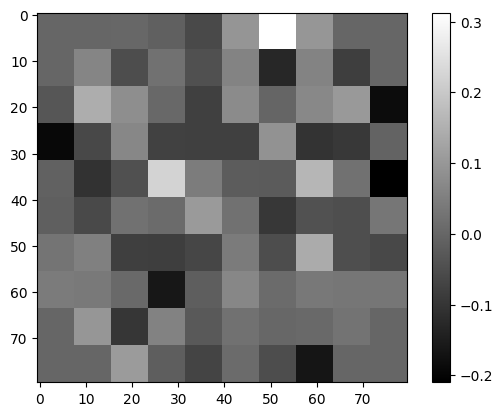

(2020, 2, 80, 80) (8080, 2, 80, 80)
(2020, 80, 80) (8080, 80, 80)


In [70]:
rng =  np.random.default_rng(rng_SEED)
n = WFS.shape[0]
train_id = np.zeros(n,np.bool)
train_id[rng.choice(n,int(train_split*n),replace=False)] = True

x_train = WFS[train_id,:,:,:]
x_val = WFS[~train_id,:,:,:]

y_train = iPSF[train_id,:,:]
y_val = iPSF[~train_id,:,:]

plt.close(0)
plt.figure(0)
plt.imshow(x_train[5,0,:,:], cmap='gray')
plt.colorbar()
plt.show()

print(x_val.shape,x_train.shape)
print(y_val.shape,y_train.shape)

## Unet

In [71]:

# model = unet.build_unet(input_shape=(2,80,80), n_channels_out=1)
# device = torch.device("cuda:0" if GPU and torch.cuda.is_available() else "cpu")


import copy
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch.optim import SGD
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import roc_auc_score

import TM26_unet as unet

In [ ]:
device = torch.device("cuda:0" if GPU and torch.cuda.is_available() else "cpu")
model = unet.build_unet(input_shape=(80, 80, 2), n_channels_out=1).to(device) # input shape is (width, height, channel) where channel is WFSx and WFSy

# TODO: à revoir
weight_path = outputDir+"{}_weights.best.pth".format("cxr_reg")

train_vol, validation_vol = x_train, x_val
train_seg, validation_seg = y_train, y_val

print(train_vol.shape)

# Convert numpy arrays to torch tensors
# TODO: Evaluate pertinence of float32
train_vol = torch.tensor(train_vol, dtype=torch.float32)
validation_vol = torch.tensor(validation_vol, dtype=torch.float32)
train_seg = torch.tensor(train_seg, dtype=torch.float32)
validation_seg = torch.tensor(validation_seg, dtype=torch.float32)

# Define batch size depending on device
batch_size = 32 if device.type == "cuda" else 12

(8080, 2, 80, 80)


## Dataloader

Shuffle = True for now in order to predict iPSFs. The temporality does not matter yet.

In [79]:
train_loader = DataLoader(TensorDataset(train_vol, train_seg), batch_size=batch_size, shuffle=True)
val_loader = DataLoader(TensorDataset(validation_vol, validation_seg), batch_size=batch_size, shuffle=False)

## Criterion and opti.

In [80]:
optimizer = SGD(model.parameters(), lr=0.001, momentum=0.9)
scheduler = ReduceLROnPlateau(optimizer, mode="min", factor=0.05, patience=3, cooldown=2, min_lr=1e-6)
criterion = unet.mse_loss


## Epoch helper

In [87]:
def run_epoch(model, loader, optimizer=None, phase="Train", epoch=0, num_epochs=1):
    is_training = optimizer is not None
    model.train() if is_training else model.eval()

    running_loss = 0.0
    running_acc = 0.0

    pbar = tqdm(
        loader,
        desc=f"{phase} {epoch + 1}/{num_epochs}",
        leave=False
    )

    for inputs, targets in pbar:
        inputs = inputs.to(device)
        targets = targets.to(device)

        if is_training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(is_training):
            outputs = model(inputs)
            loss = criterion(targets, outputs)

            if is_training:
                loss.backward()
                optimizer.step()

        probs = torch.sigmoid(outputs)
        preds = (probs > 0.5).float()
        acc = (preds == targets).float().mean().item()

        running_loss += loss.item() * inputs.size(0)
        running_acc += acc * inputs.size(0)

        # Update the loading bar with current batch values
        pbar.set_postfix(
            loss=f"{loss.item():.6f}",
            acc=f"{acc:.6f}"
        )

    epoch_loss = running_loss / len(loader.dataset)
    epoch_acc = running_acc / len(loader.dataset)

    return epoch_loss, epoch_acc

## Training param

In [82]:
num_epochs = 100
early_stopping_patience = 15
best_val_loss = np.inf
epochs_no_improve = 0
best_model_wts = copy.deepcopy(model.state_dict())

history = {
    "loss": [],
    "val_loss": [],
    "binary_accuracy": [],
    "val_binary_accuracy": [],
    "auc": [],
    "val_auc": []
}

In [ ]:
for epoch in range(num_epochs):
    train_loss, train_acc = run_epoch(
        model,
        train_loader,
        optimizer=optimizer,
        phase="Train",
        epoch=epoch,
        num_epochs=num_epochs
    )

    val_loss, val_acc = run_epoch(
        model,
        val_loader,
        optimizer=None,
        phase="Val",
        epoch=epoch,
        num_epochs=num_epochs
    )

    history["loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["binary_accuracy"].append(train_acc)
    history["val_binary_accuracy"].append(val_acc)

    print(
        f"Epoch {epoch + 1}/{num_epochs} - "
        f"loss: {train_loss:.6f} - val_loss: {val_loss:.6f} - "
        f"acc: {train_acc:.6f} - val_acc: {val_acc:.6f}"
    )

    # Update learning rate based on validation loss
    scheduler.step(val_loss)

    # Save the best model
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_no_improve = 0
        best_model_wts = copy.deepcopy(model.state_dict())
        torch.save(model.state_dict(), weight_path)
        print(f"Saved best model to {weight_path}")
    else:
        epochs_no_improve += 1

    # Stop training early if validation loss does not improve
    if epochs_no_improve >= early_stopping_patience:
        print("Early stopping triggered")
        break

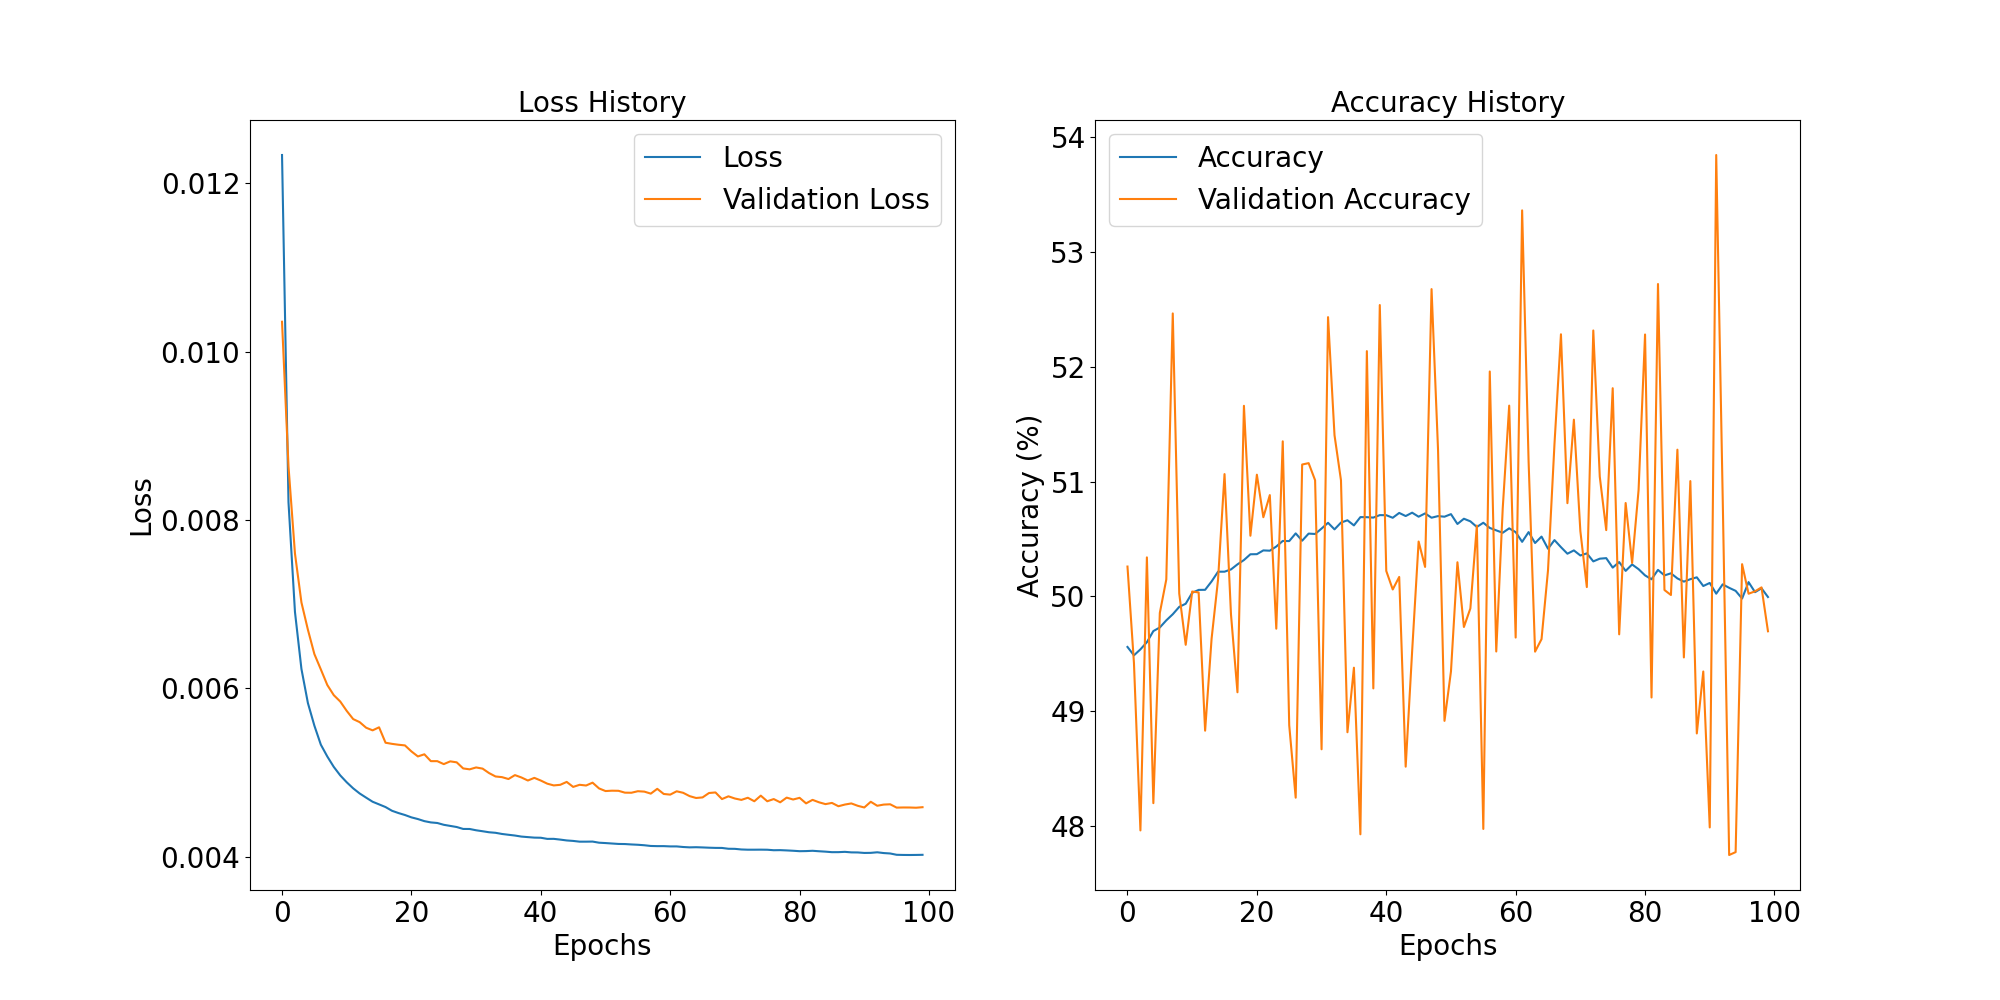

In [120]:
# Load the best model weights
model.load_state_dict(best_model_wts)
torch.save(model.state_dict(), outputDir + "/model.weights.pth")


# Plot loss and accuracy history
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 10))

ax1.plot(history["loss"], "-", label="Loss")
ax1.plot(history["val_loss"], "-", label="Validation Loss")
ax1.set_xlabel("Epochs")
ax1.set_ylabel("Loss")
ax1.set_title("Loss History")
ax1.legend()

ax2.plot(100 * np.array(history["binary_accuracy"]), "-", label="Accuracy")
ax2.plot(100 * np.array(history["val_binary_accuracy"]), "-", label="Validation Accuracy")
ax2.set_xlabel("Epochs")
ax2.set_ylabel("Accuracy (%)")
ax2.set_title("Accuracy History")
ax2.legend()

plt.rc("font", size=SMALL_SIZE)
plt.rc("axes", titlesize=SMALL_SIZE)
plt.rc("axes", labelsize=MEDIUM_SIZE)
plt.rc("xtick", labelsize=SMALL_SIZE)
plt.rc("ytick", labelsize=SMALL_SIZE)
plt.rc("legend", fontsize=SMALL_SIZE)
plt.rc("figure", titlesize=BIGGER_SIZE)

plt.savefig(outputDir + "/loss.png")


(2, 80, 80)


(2, 80, 80)


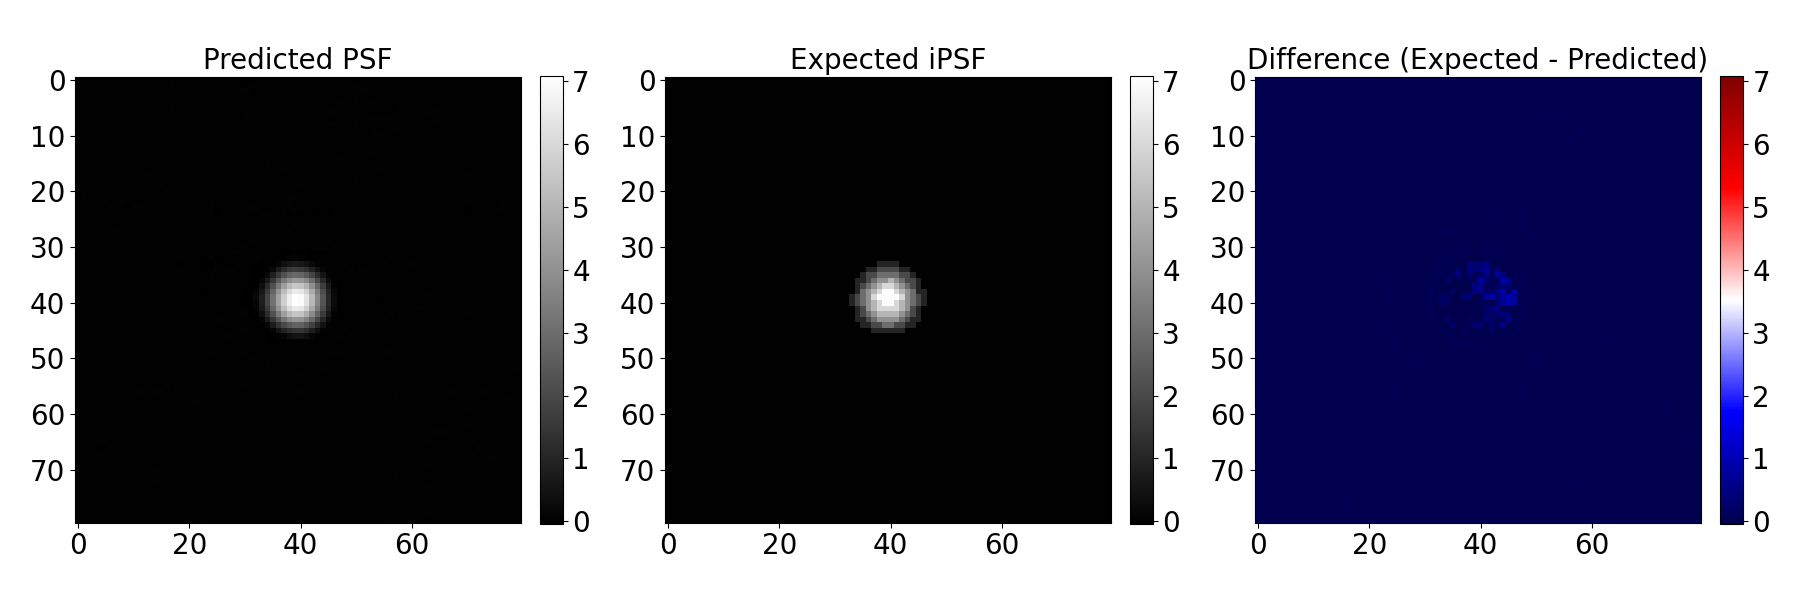

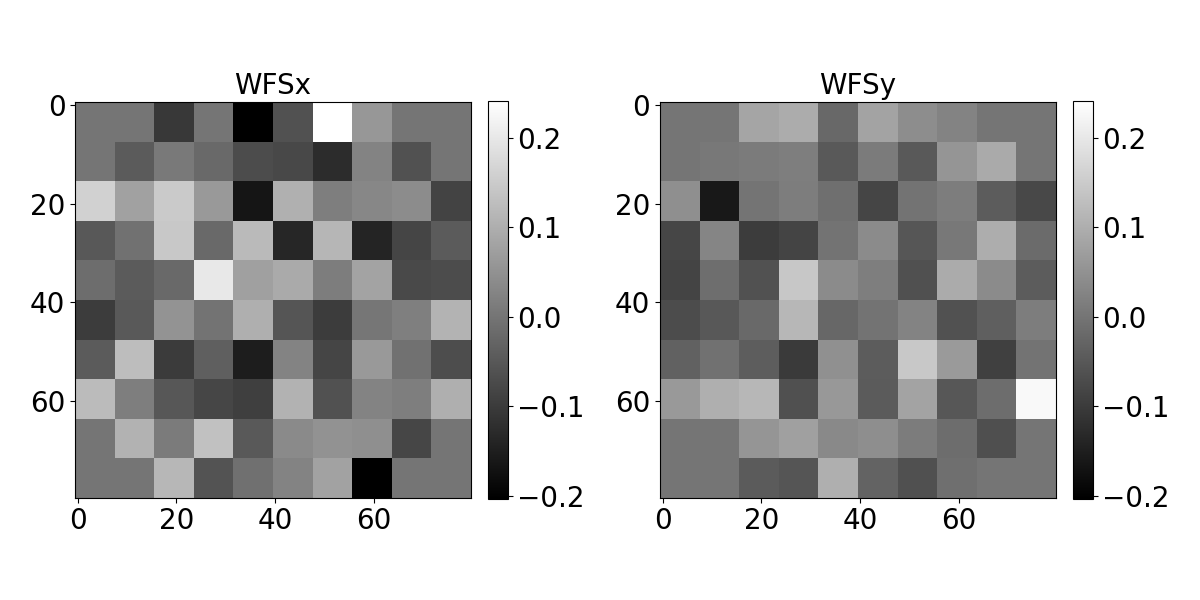

In [122]:
iteration_evaluation = 0

model.eval()
x = x_val[iteration_evaluation]

print(x.shape)
x = torch.tensor(x, dtype=torch.float32).unsqueeze(0).to(device)
# Run inference
with torch.no_grad():
    y_pred = model(x)
inference = y_pred.squeeze().cpu().numpy()


plt.close('all')
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

vmin = min(float(inference.min()), float(y_val[iteration_evaluation].min()))
vmax = max(float(inference.max()), float(y_val[iteration_evaluation].max()))

im0 = axes[0].imshow(inference, cmap='gray', vmin=vmin, vmax=vmax)
axes[0].set_title("Predicted PSF")
fig.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

im1 = axes[1].imshow(y_val[iteration_evaluation].astype(float), cmap='gray', vmin=vmin, vmax=vmax)
axes[1].set_title("Expected iPSF")
fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

diff = y_val[iteration_evaluation].astype(float) - inference
im2 = axes[2].imshow(diff, cmap='seismic', vmin=vmin, vmax=vmax)
axes[2].set_title("Difference (Expected - Predicted)")
fig.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.savefig(outputDir + "/pred_expected_difference_1x3.png", dpi=150)





vmin = min(float(x_val[iteration_evaluation, 0, :, :].min()), float(x_val[iteration_evaluation, 1, :, :].min()))
vmax = max(float(x_val[iteration_evaluation, 0, :, :].max()), float(x_val[iteration_evaluation, 1, :, :].max()))

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

im0 = axes[0].imshow(x_val[iteration_evaluation, 0, :, :], cmap='gray', vmin=vmin, vmax=vmax)
axes[0].set_title("WFSx")
fig.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

im1 = axes[1].imshow(x_val[iteration_evaluation, 1, :, :], cmap='gray', vmin=vmin, vmax=vmax)
axes[1].set_title("WFSy")
fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.savefig(outputDir + "/WFS_x_y.png", dpi=150)
